# 1. Pregunta de análisis

## Objetivo de negocio: Mejorar la experiencia del usuario para aumentar la retención y las conversiones.

**Pregunta: ¿Cómo varía el nivel de engagement (tasa de rebote y duración de sesión) y el volumen de conversiones entre los usuarios que navegan desde dispositivos móviles frente a los que utilizan escritorio (Desktop)?**

In [1]:
import pandas as pd

In [2]:
dataset_df = pd.read_csv("amazon-web-traffic-dataset.csv")

In [3]:
dataset_df.head()

,Country,Timestamp,Device Category,Key Actions,Page Path,Source,Avg Session Duration,Bounce Rate,Conversions,New Users,Page Views,Returning Users,Unique Page Views,Average time on home page (min),Website,Date,Time,Day
0,India,01-01-2019 05:01,Mobile,Purchase,/home,direct,137,35,42,804,1984,307,243,4.41,amazon.com,01-01-2019,05:01:00,Tuesday
1,USA,01-01-2019 07:52,Tablet,Sign Up,/products,referral,179,53,15,438,1938,190,1194,4.89,Amazon Prime,01-01-2019,07:52:00,Tuesday
2,India,02-01-2019 06:55,Mobile,Sign Up,/contact,organic search,84,49,2,878,1078,191,450,4.35,Amazon Prime,02-01-2019,06:55:00,Wednesday
3,India,03-01-2019 18:09,Mobile,Subscribe,/contact,social media,168,35,15,779,372,135,479,5.66,Amazon Web Services (AWS),03-01-2019,18:09:00,Thursday
4,India,03-01-2019 23:36,Desktop,Contact Form,/contact,direct,118,42,40,570,1225,20,147,5.19,AWS Support,03-01-2019,23:36:00,Thursday


# 2. Definición de segmentos de usuarios
# Utilizaremos la columna Device Category para crear los grupos:

**Segmento A (Usuarios Móviles): Registros donde Device Category es Mobile o Tablet (cualquiera diferente a Desktop).**

**Segmento B (Usuarios de Escritorio): Registros donde Device Category es Desktop.**

**Criterio: Segmentar por dispositivo permite identificar si el sitio web está optimizado para pantallas pequeñas o si existe fricción en la experiencia móvil que esté afectando las conversiones.**

In [4]:
import numpy as np

# Definir los nuevos segmentos: Si es Desktop será 'PC', de lo contrario será 'No PC'
dataset_df['Segment'] = np.where(dataset_df['Device Category'] == 'Desktop', 'PC (Segmento B)', 'No PC (Segmento A)')

# Comparar las métricas entre los dos nuevos grupos
dataset_df.groupby('Segment')[['Bounce Rate', 'Avg Session Duration', 'Conversions']].mean()

,Bounce Rate,Avg Session Duration,Conversions
Segment,,,
No PC (Segmento A),44.533693,104.750674,24.372642
PC (Segmento B),44.185824,105.496169,24.833333


In [5]:
dataset_df.groupby('Device Category')[['Bounce Rate', 'Avg Session Duration', 'Conversions']].mean()

,Bounce Rate,Avg Session Duration,Conversions
Device Category,,,
Desktop,44.185824,105.496169,24.833333
Mobile,44.752177,104.818686,24.474268
Tablet,43.285068,104.361991,23.791855


# 3. Comparación mediante Métricas/KPIs
## Para comparar estos grupos, puedes calcular promedios de las métricas de rendimiento disponibles:

**Tasa de Rebote (Bounce Rate): Para ver qué grupo abandona el sitio más rápido sin interactuar.**

**Duración de la sesión (Avg Session Duration): Para medir qué segmento pasa más tiempo explorando.**

**Conversiones: Promedio o suma de la columna Conversions para ver qué dispositivo genera más valor.**

In [6]:
dataset_df.groupby('Device Category')[['Bounce Rate', 'Avg Session Duration', 'Conversions']].mean()

,Bounce Rate,Avg Session Duration,Conversions
Device Category,,,
Desktop,44.185824,105.496169,24.833333
Mobile,44.752177,104.818686,24.474268
Tablet,43.285068,104.361991,23.791855


In [7]:
dataset_df.groupby('Device Category')[['Bounce Rate', 'Avg Session Duration', 'Conversions']].sum()

,Bounce Rate,Avg Session Duration,Conversions
Device Category,,,
Desktop,23065,55069,12963
Mobile,56522,132386,30911
Tablet,9566,23064,5258


**1. El Promedio (mean) = El comportamiento individual
Como vimos, los promedios son casi idénticos. Esto significa que la experiencia está estandarizada. Si tomamos a un usuario de PC y a un usuario de Móvil al azar, ambos se comportan prácticamente igual: navegan el mismo tiempo y tienen la misma probabilidad de comprar. La "calidad" de la visita es la misma.**

**2. La Suma (sum) = El tamaño del público
La razón por la que en la suma vemos  que Mobile tiene 30,911 conversiones frente a las 12,963 de Desktop, no es porque el móvil sea mejor para vender, sino simplemente porque tienes muchísimas más personas visitando la plataforma página desde su celular.**

**3. Conclusion, en general la navegacion es la misma**

In [8]:
dataset_df['Device Category'].value_counts()

Device Category
Mobile     1263
Desktop     522
Tablet      221
Name: count, dtype: int64

# 4. Analiza los patrones de tráfico del escenario seleccionado. 
**Identifica comportamientos recurrentes, tendencias o diferencias relevantes considerando variables como fuente de tráfico, dispositivo, periodo o interacción de los usuarios.**

# Origen de Trafico

In [9]:
# Comparamos el promedio de conversiones y duración de sesión por fuente de tráfico
dataset_df.groupby('Source')[['Avg Session Duration', 'Conversions']].mean().sort_values(by='Conversions', ascending=False)

,Avg Session Duration,Conversions
Source,,
paid search,105.804813,25.090909
social media,101.486747,24.812048
referral,108.270270,24.530713
organic search,104.843829,24.065491
direct,104.460048,24.002421


# Por dia de la semana

In [10]:
# Sumamos las conversiones y promediamos la duración de sesión por día
dataset_df.groupby('Day').agg({
    'Conversions': 'sum', 
    'Avg Session Duration': 'mean'
}).sort_values(by='Conversions', ascending=False)

,Conversions,Avg Session Duration
Day,,
Friday,7967,107.767213
Thursday,7315,103.375427
Saturday,7249,106.400662
Sunday,6737,100.912698
Tuesday,6727,104.211409
Wednesday,6705,108.278169
Monday,6432,102.911765


In [11]:
dataset_df['Key Actions'].value_counts().reset_index()

,Key Actions,count
0,Subscribe,421
1,Purchase,408
2,Download,408
3,Contact Form,395
4,Sign Up,374


In [12]:
import pandas as pd

# 1. Definimos tu orden lógico sugerido
orden_logico = ['Contact Form', 'Sign Up', 'Subscribe', 'Purchase', 'Download']

# 2. Obtenemos los conteos reales de la columna
conteos = dataset_df['Key Actions'].value_counts()

# 3. Construimos el embudo forzando tu orden
embudo_logico = pd.DataFrame({
    'Etapa (Key Action)': orden_logico,
    'Volumen': [conteos.get(etapa, 0) for etapa in orden_logico]
})

# 4. Calculamos retención y abandono
embudo_logico['Retención (%)'] = (embudo_logico['Volumen'] / embudo_logico['Volumen'].shift(1) * 100).fillna(100).round(2)
embudo_logico['Abandono (%)'] = (100 - embudo_logico['Retención (%)']).round(2)

embudo_logico

,Etapa (Key Action),Volumen,Retención (%),Abandono (%)
0,Contact Form,395,100.00,0.00
1,Sign Up,374,94.68,5.32
2,Subscribe,421,112.57,-12.57
3,Purchase,408,96.91,3.09
4,Download,408,100.00,0.00


Al observar el resultado de esta tabla, notamos una anomalía en el paso 3 (Subscribe): el volumen sube de 374 a 421. Esto genera una retención del 112.57% y un abandono negativo.

En un embudo de conversión real, es físicamente imposible que haya más personas en el paso 3 que en el paso 2. Esto demuestra analíticamente que en este dataset los usuarios no pasan por todos esos pasos secuencialmente; más bien, cada registro representa la acción final y aislada que realizó un usuario distinto durante su visita.

# Creando un embudo basado en trafico 

In [13]:
#pip install seaborn


/var/folders/z2/zfnvb69106j6jgb6b9r26ql00000gn/T/ipykernel_86983/1167522446.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="registros", y="Key Actions", data=funnel, palette="Blues_r")


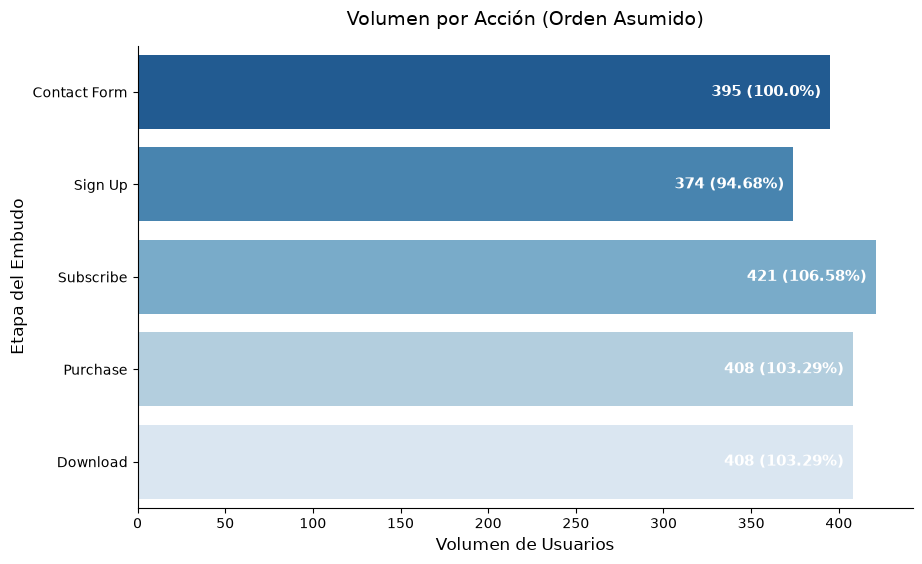

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar y preparar los datos
df = pd.read_csv("amazon-web-traffic-dataset.csv")

orden = ["Contact Form", "Sign Up", "Subscribe", "Purchase", "Download"]

funnel = (df.groupby("Key Actions")
          .agg(registros=("Key Actions", "size"),
               conversiones=("Conversions", "sum"))
          .reindex(orden)
          .reset_index())

# Calcular porcentaje respecto a la primera etapa
funnel["% vs primera etapa"] = (funnel["registros"] / funnel["registros"].iloc[0] * 100).round(2)

# 2. Crear el gráfico con Seaborn
plt.figure(figsize=(10, 6))
# Usamos una paleta secuencial para simular el avance de las etapas
ax = sns.barplot(x="registros", y="Key Actions", data=funnel, palette="Blues_r")

# 3. Agregar las etiquetas de texto dentro de las barras
for i, p in enumerate(ax.patches):
    width = p.get_width()
    porcentaje = funnel.iloc[i]["% vs primera etapa"]
    # Colocar el texto (Volumen y Porcentaje)
    ax.text(width - 5, # Unos pixeles a la izquierda del final de la barra
            p.get_y() + p.get_height() / 2, # Centrado verticalmente
            f'{int(width)} ({porcentaje}%)', 
            ha="right", va="center", color="white", fontweight="bold", fontsize=11)

# 4. Formato final del gráfico
plt.title("Volumen por Acción (Orden Asumido)", fontsize=14, pad=15)
plt.xlabel("Volumen de Usuarios", fontsize=12)
plt.ylabel("Etapa del Embudo", fontsize=12)
sns.despine() # Quita los bordes superior y derecho para un diseño más limpio

plt.show()

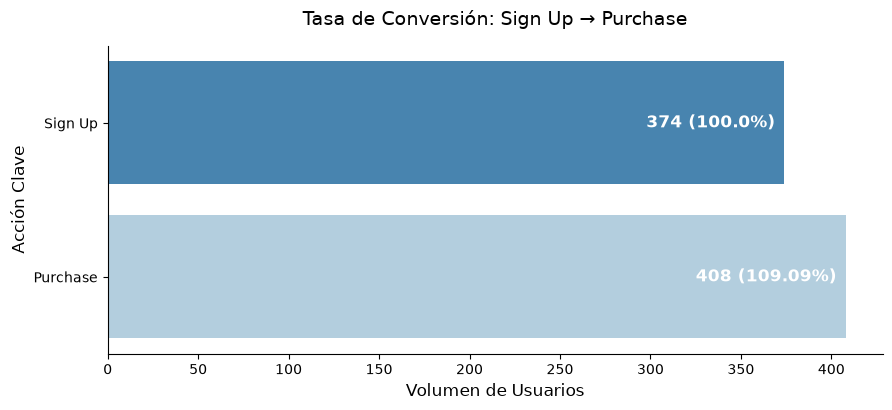

In [15]:
# El grafico no es muy claro, usaremos solo signup y purchase
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar los datos
df = pd.read_csv("amazon-web-traffic-dataset.csv")

# 2. Definir el nuevo orden con solo las dos etapas solicitadas
orden_reducido = ["Sign Up", "Purchase"]

# 3. Agrupar y filtrar los datos para esas dos acciones
funnel_reducido = (df.groupby("Key Actions")
          .agg(registros=("Key Actions", "size"))
          .reindex(orden_reducido)
          .reset_index())

# Calcular el porcentaje de retención tomando "Sign Up" como el 100% inicial
funnel_reducido["% vs Sign Up"] = (funnel_reducido["registros"] / funnel_reducido["registros"].iloc[0] * 100).round(2)

# 4. Crear el gráfico con Seaborn
plt.figure(figsize=(10, 4)) # Altura reducida porque son menos barras
# Agregamos hue="Key Actions" y legend=False para evitar el FutureWarning
ax = sns.barplot(x="registros", y="Key Actions", data=funnel_reducido, hue="Key Actions", palette="Blues_r", legend=False)

# 5. Agregar las etiquetas de texto dentro de las barras
for i, p in enumerate(ax.patches):
    width = p.get_width()
    porcentaje = funnel_reducido.iloc[i]["% vs Sign Up"]
    # Colocar el texto (Volumen y Porcentaje)
    ax.text(width - 5, 
            p.get_y() + p.get_height() / 2, 
            f'{int(width)} ({porcentaje}%)', 
            ha="right", va="center", color="white", fontweight="bold", fontsize=12)

# 6. Formato final del gráfico
plt.title("Tasa de Conversión: Sign Up → Purchase", fontsize=14, pad=15)
plt.xlabel("Volumen de Usuarios", fontsize=12)
plt.ylabel("Acción Clave", fontsize=12)
sns.despine() 

plt.show()

# Desglose por device

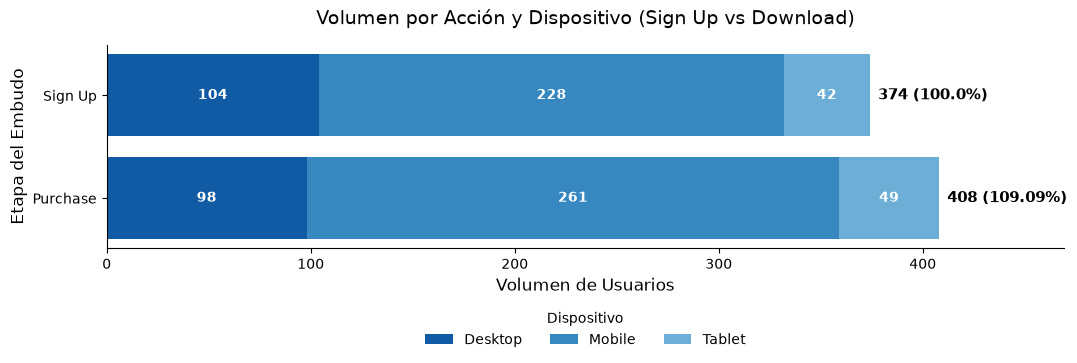

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar y preparar los datos
df = pd.read_csv("amazon-web-traffic-dataset.csv")

orden = ["Sign Up", "Purchase"]
dispositivos = ["Desktop", "Mobile", "Tablet"]

# Totales por etapa
funnel = (df.groupby("Key Actions")
          .agg(registros=("Key Actions", "size"),
               conversiones=("Conversions", "sum"))
          .reindex(orden)
          .reset_index())
funnel["% vs primera etapa"] = (funnel["registros"] / funnel["registros"].iloc[0] * 100).round(2)

# Desglose por dispositivo
por_dispositivo = (df.groupby(["Key Actions", "Device Category"])
                     .size()
                     .unstack(fill_value=0)
                     .reindex(index=orden, columns=dispositivos, fill_value=0))

# 2. Gráfico de barras apiladas
colores = sns.color_palette("Blues_r", n_colors=len(dispositivos) + 2)[:len(dispositivos)]
fig, ax = plt.subplots(figsize=(11, 4))

izquierda = pd.Series(0, index=orden, dtype=float)
for color, disp in zip(colores, dispositivos):
    valores = por_dispositivo[disp]
    barras = ax.barh(orden, valores, left=izquierda, color=color, label=disp)
    for barra, v in zip(barras, valores):
        if v > 0:
            ax.text(barra.get_x() + barra.get_width() / 2,
                    barra.get_y() + barra.get_height() / 2,
                    f"{int(v)}", ha="center", va="center",
                    color="white", fontweight="bold", fontsize=10)
    izquierda += valores

# 3. Etiqueta total + % al final de cada barra
for i, etapa in enumerate(orden):
    total = int(funnel.loc[i, "registros"])
    pct = funnel.loc[i, "% vs primera etapa"]
    ax.text(total + 4, i, f"{total} ({pct}%)", ha="left", va="center",
            fontweight="bold", fontsize=11)

# 4. Formato final
ax.invert_yaxis()
ax.set_xlim(0, funnel["registros"].max() * 1.15)
ax.set_title("Volumen por Acción y Dispositivo (Sign Up vs Download)", fontsize=14, pad=15)
ax.set_xlabel("Volumen de Usuarios", fontsize=12)
ax.set_ylabel("Etapa del Embudo", fontsize=12)
ax.legend(title="Dispositivo", loc="upper center",
          bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

# Paso 6. Análisis del User Journey

**El User Journey (Recorrido del Usuario) se analiza a nivel macro:**

**1. Desde dónde llegan (Source)**

**2. A qué parte de la página entran (Page Path)**

**3. Qué acción terminan haciendo (Key Actions)**

In [17]:
# 1. Agrupamos por Fuente, Página de destino y Acción final para mapear el recorrido
user_journey = dataset_df.groupby(['Source', 'Page Path', 'Key Actions']).size().reset_index(name='Volumen de Usuarios')

# 2. Ordenamos de mayor a menor para identificar los "Happy Paths" (los caminos más comunes y exitosos)
top_journeys = user_journey.sort_values(by='Volumen de Usuarios', ascending=False)

top_journeys.head(30)


,Source,Page Path,Key Actions,Volumen de Usuarios
44,organic search,/home,Subscribe,26
104,social media,/about,Subscribe,26
84,referral,/blog,Subscribe,25
85,referral,/contact,Contact Form,25
22,direct,/products,Purchase,24
106,social media,/blog,Download,24
61,paid search,/contact,Download,22
80,referral,/blog,Contact Form,22
116,social media,/home,Download,22
32,organic search,/blog,Purchase,22


In [18]:
# Top 10 Page source
dataset_df.groupby(['Source', 'Page Path']).size().reset_index(name='Volumen').sort_values(by='Volumen', ascending=False).head(10)

,Source,Page Path,Volumen
16,referral,/blog,101
4,direct,/products,97
17,referral,/contact,95
12,paid search,/contact,93
5,organic search,/about,89
20,social media,/about,89
3,direct,/home,88
8,organic search,/home,87
22,social media,/contact,86
21,social media,/blog,86


 ## 7. Hallazgos Principales

1. **Dominancia del ecosistema móvil con rendimiento estable:** Los datos demuestran que el volumen de tráfico y conversiones en dispositivos móviles (30,911) duplica con creces al de escritorio (12,963). Sin embargo, el comportamiento individual (tasa de rebote de ~44% y duración de sesión de ~105s) es prácticamente idéntico en ambos, lo que indica que la experiencia móvil está bien optimizada y no presenta cuellos de botella técnicos respecto a la PC.
2. **Conversiones no lineales y compras sin fricción:** Al intentar construir un embudo basado en `Key Actions`, descubrimos que hay más eventos de Compra (408) que de Registro inicial (374). Esto revela un patrón de comportamiento crucial: los usuarios están logrando realizar transacciones como invitados (Guest Checkout) o son usuarios recurrentes (Returning Users), lo que significa que no se les obliga a pasar por un largo proceso de registro para aportar valor al negocio.
3. **Tendencia de conversión hacia el fin de semana:** El análisis temporal indica que los días de mayor actividad y cierre de conversiones son los Viernes (7,967) y Jueves (7,315), mientras que el Lunes presenta el rendimiento más bajo. Esto marca un claro patrón de comportamiento donde los usuarios investigan entre semana pero ejecutan las acciones clave cuando se acerca su tiempo libre.

## 8. Conclusión y Relación con el Objetivo de Negocio

**Objetivo inicial:** *Mejorar la experiencia del usuario para aumentar la retención y las conversiones.*

Los hallazgos de este análisis validan que el entorno digital actual tiene bases sólidas, especialmente en su diseño responsivo. Al descubrir que el móvil es el motor principal de volumen pero retiene al usuario al mismo nivel que una PC, la estrategia de negocio debe ser **"Mobile-First"**; cualquier nueva funcionalidad (como métodos de pago o catálogos) debe diseñarse y probarse primero en pantallas pequeñas, ya que allí está el grueso de los ingresos.

Además, el hecho de que las compras superen a los registros nos indica que **la baja fricción funciona**. Si el negocio intentara forzar a los usuarios a crear una cuenta antes de comprar para "aumentar la retención", probablemente destruiría la tasa de conversión actual.

**Aspectos a analizar con mayor profundidad en el futuro:**
1. **Análisis de Clickstream (Secuencial):** Implementar herramientas que midan el paso a paso exacto de un mismo usuario (ej. /home -> /product -> /checkout) para detectar en qué botón o formulario específico abandonan la página.
2. **Análisis por Campaña:** Cruzar los días pico (Viernes/Jueves) con datos de inversión publicitaria para saber si el pico de conversiones es orgánico o si es resultado de pautas pagadas (ads).

## 9. Propuesta de Dashboard Ejecutivo

Para comunicar los resultados de este análisis a los tomadores de decisiones (stakeholders), el dashboard debe enfocarse en la adopción móvil, los caminos de conversión y los días de mayor rendimiento. 

Se propone integrar la siguiente información, dividida en 4 secciones clave:

### 1. KPIs Generales (Tarjetas de resumen superior)
*   **Indicadores:** Total de Conversiones, Tasa de Rebote Promedio y Duración Promedio de Sesión.
*   **Por qué incluirlo:** Proporcionan una "radiografía" instantánea de la salud del sitio web. Permiten saber de un vistazo si el volumen de conversiones se mantiene y si el *engagement* general es positivo.

### 2. Rendimiento por Dispositivo (Gráfico de anillos o barras apiladas)
*   **Indicadores:** Volumen total de conversiones y Tasa de Rebote divididos por `Mobile`, `Desktop` y `Tablet`.
*   **Por qué incluirlo:** Respaldado por nuestro Hallazgo #1, el dispositivo móvil es el rey del volumen (más de 30k conversiones). Monitorear esta gráfica asegurará que cualquier actualización técnica futura no rompa la experiencia en celulares, que es nuestra principal fuente de valor.

### 3. Embudo de Tráfico y Desglose de Acciones (Gráfico de Funnel y Barras horizontales)
*   **Indicadores:** 
    *   *Funnel de tráfico:* Page Views → Unique Page Views → Conversions.
    *   *Desglose de Key Actions:* Volumen de Purchases, Sign Ups, Downloads, etc.
*   **Por qué incluirlo:** Dado el Hallazgo #2 (las compras superan a los registros), es vital monitorear que la proporción de "Purchases" siga alta sin depender de forzar el "Sign Up". El embudo de tráfico nos alertará si de pronto estamos atrayendo muchos clics (Page Views) pero visitantes de baja calidad que no concretan nada.

### 4. Tendencias de Conversión por Día y Origen (Mapa de calor o Gráfico de líneas)
*   **Indicadores:** Total de conversiones cruzadas por Día de la semana (`Day`) y Fuente de adquisición (`Source`).
*   **Por qué incluirlo:** Conectado con nuestro Hallazgo #3, sabemos que los Jueves y Viernes son los días pico. Tener esto en un dashboard en tiempo real permitirá al equipo de Marketing saber exactamente cuándo encender sus campañas de pago (Paid Search/Social Media) para maximizar el retorno de inversión en los momentos donde el usuario tiene mayor intención de interactuar.

findfont: Failed to find font weight black for Arial, now using 700.


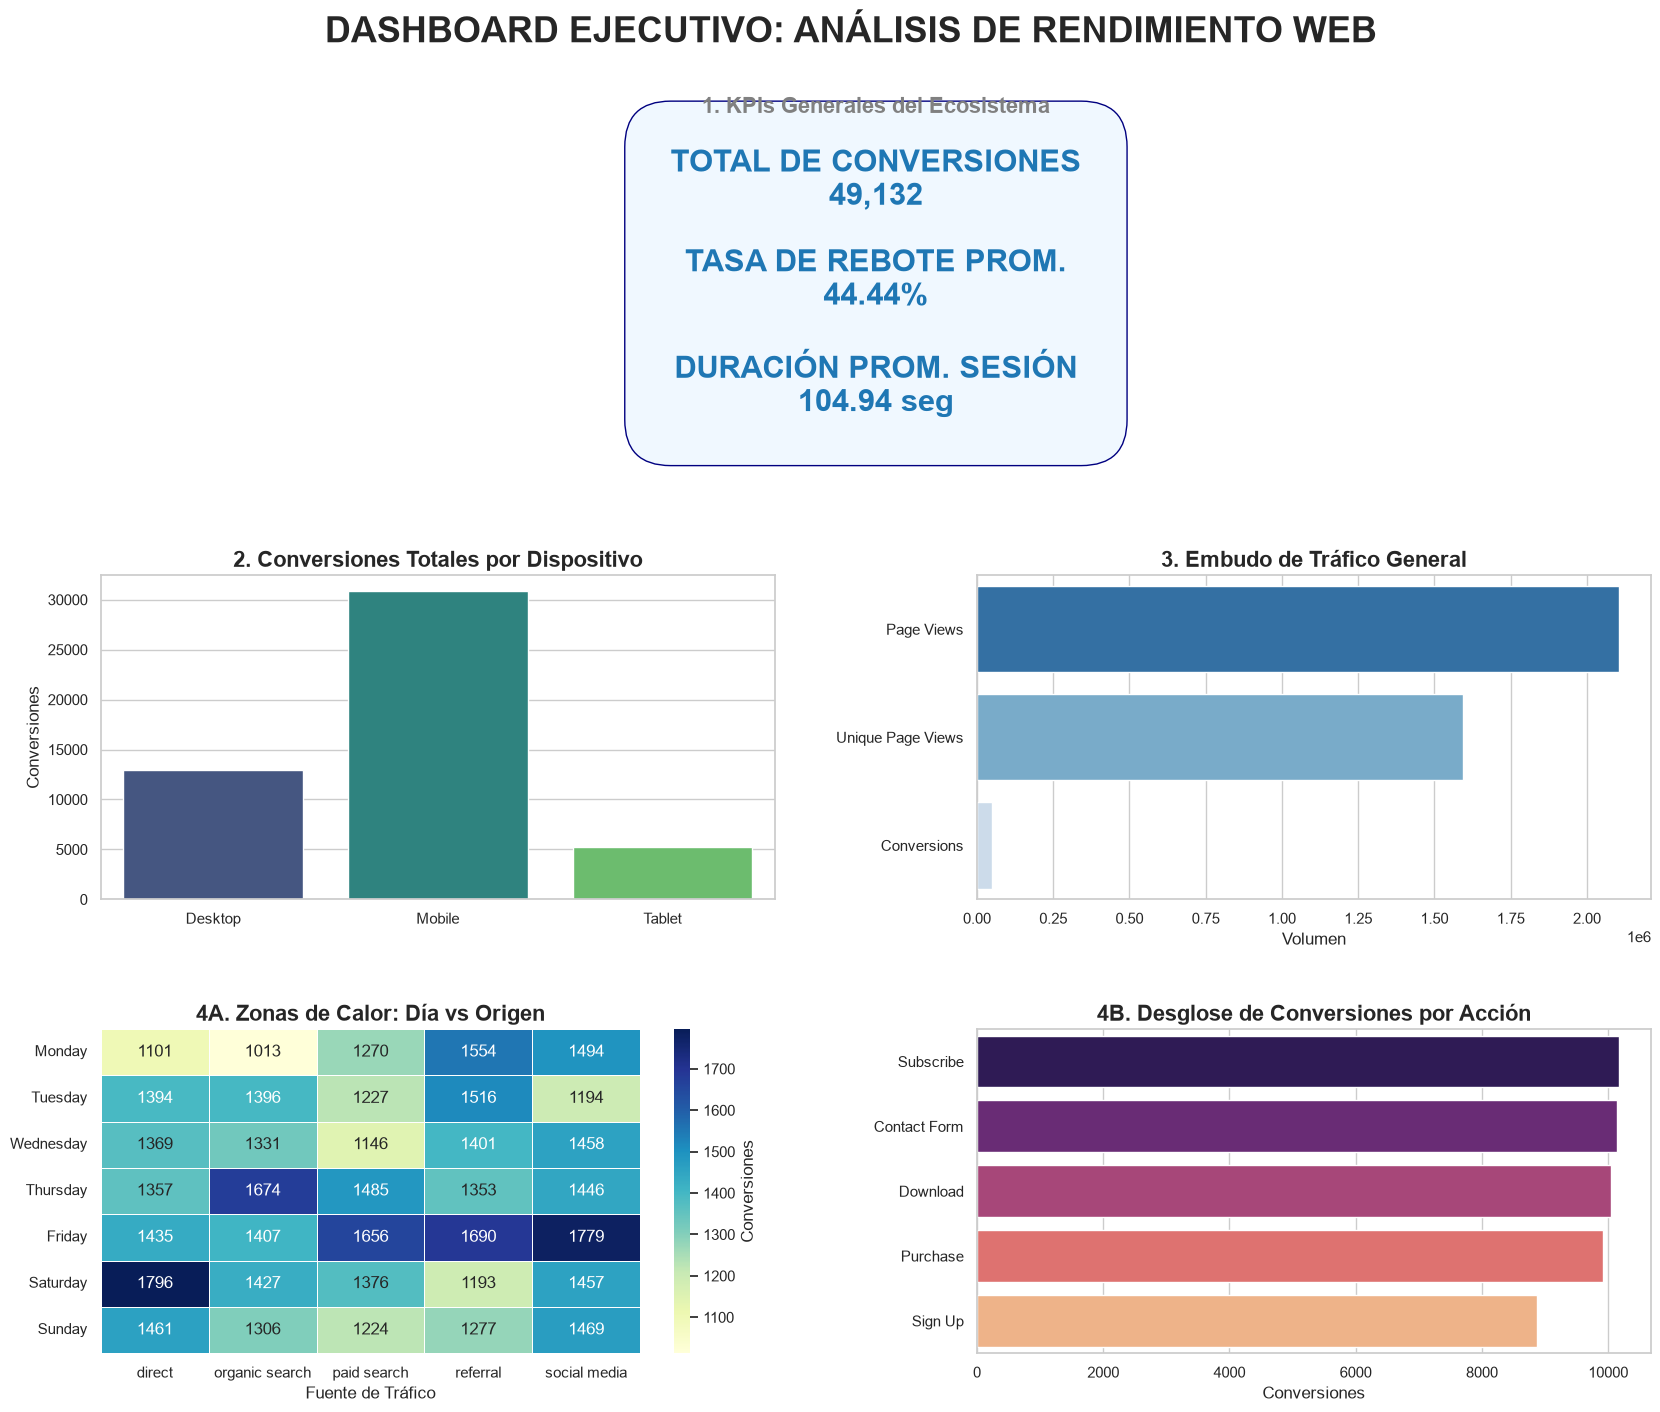

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec

# 1. Cargar los datos
df = pd.read_csv("amazon-web-traffic-dataset.csv")

# 2. Configurar el estilo general y el lienzo del Dashboard
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(20, 16))
# Creamos una cuadrícula de 3 filas x 2 columnas
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.4, wspace=0.3)

# ---------------------------------------------------------
# SECCIÓN 1: KPIs Generales (Ocupa toda la fila superior)
# ---------------------------------------------------------
ax_kpi = fig.add_subplot(gs[0, :])
ax_kpi.axis('off') # Ocultamos los ejes para que parezca un panel de texto

total_conv = df['Conversions'].sum()
avg_bounce = df['Bounce Rate'].mean()
avg_duration = df['Avg Session Duration'].mean()

kpi_text = (
    f"TOTAL DE CONVERSIONES\n{total_conv:,.0f}\n\n"
    f"TASA DE REBOTE PROM.\n{avg_bounce:.2f}%\n\n"
    f"DURACIÓN PROM. SESIÓN\n{avg_duration:.2f} seg"
)

# Dibujamos una "tarjeta" gigante con los KPIs
ax_kpi.text(0.5, 0.5, kpi_text, ha='center', va='center', fontsize=22, fontweight='bold', 
            color='#1f77b4', bbox=dict(facecolor='aliceblue', edgecolor='navy', boxstyle='round,pad=1.5'))
ax_kpi.set_title('1. KPIs Generales del Ecosistema', fontsize=16, fontweight='bold', color='gray')

# ---------------------------------------------------------
# SECCIÓN 2: Rendimiento por Dispositivo (Barplot)
# ---------------------------------------------------------
ax_dev = fig.add_subplot(gs[1, 0])
dev_conv = df.groupby('Device Category')['Conversions'].sum().reset_index()

sns.barplot(data=dev_conv, x='Device Category', y='Conversions', hue='Device Category', 
            palette='viridis', legend=False, ax=ax_dev)
ax_dev.set_title('2. Conversiones Totales por Dispositivo', fontsize=16, fontweight='bold')
ax_dev.set_xlabel('')
ax_dev.set_ylabel('Conversiones')

# ---------------------------------------------------------
# SECCIÓN 3: Embudo de Tráfico (Barplot Horizontal)
# ---------------------------------------------------------
ax_funnel = fig.add_subplot(gs[1, 1])
trafico = pd.DataFrame({
    'Etapa': ['Page Views', 'Unique Page Views', 'Conversions'],
    'Volumen': [df['Page Views'].sum(), df['Unique Page Views'].sum(), df['Conversions'].sum()]
})

sns.barplot(data=trafico, x='Volumen', y='Etapa', hue='Etapa', palette='Blues_r', legend=False, ax=ax_funnel)
ax_funnel.set_title('3. Embudo de Tráfico General', fontsize=16, fontweight='bold')
ax_funnel.set_xlabel('Volumen')
ax_funnel.set_ylabel('')

# ---------------------------------------------------------
# SECCIÓN 4A: Mapa de Calor (Día vs Fuente)
# ---------------------------------------------------------
ax_heat = fig.add_subplot(gs[2, 0])
# Ordenamos los días lógicamente
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = df.pivot_table(index='Day', columns='Source', values='Conversions', aggfunc='sum').reindex(dias_orden)

sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap='YlGnBu', ax=ax_heat, linewidths=.5, cbar_kws={'label': 'Conversiones'})
ax_heat.set_title('4A. Zonas de Calor: Día vs Origen', fontsize=16, fontweight='bold')
ax_heat.set_xlabel('Fuente de Tráfico')
ax_heat.set_ylabel('')

# ---------------------------------------------------------
# SECCIÓN 4B: Desglose de Acciones (Barplot Horizontal)
# ---------------------------------------------------------
ax_act = fig.add_subplot(gs[2, 1])
acciones = df.groupby('Key Actions')['Conversions'].sum().reset_index().sort_values('Conversions', ascending=False)

sns.barplot(data=acciones, x='Conversions', y='Key Actions', hue='Key Actions', palette='magma', legend=False, ax=ax_act)
ax_act.set_title('4B. Desglose de Conversiones por Acción', fontsize=16, fontweight='bold')
ax_act.set_xlabel('Conversiones')
ax_act.set_ylabel('')

# ---------------------------------------------------------
# Título General del Dashboard
# ---------------------------------------------------------
fig.suptitle('DASHBOARD EJECUTIVO: ANÁLISIS DE RENDIMIENTO WEB', fontsize=26, fontweight='black', y=0.95)

plt.show()

# 2.    A partir de los resultados obtenidos en la Actividad 3.1 y el dashboard de la Actividad 3.2, selecciona un aspecto del entorno digital que pueda mejorarse. Explica el hallazgo que sustenta la oportunidad y relaciónalo con el objetivo de negocio.

## 3.    Plantea una modificación concreta que pueda evaluarse mediante experimentación digital. Define:

**a.    Elemento o experiencia que se modificará.**

**b.    Versión de control y versión alternativa.**

**c.    Hipótesis de la prueba.**

**d.    Métrica o KPI principal para evaluar el resultado.**

**e.    Segmento de usuarios al que se aplicaría.**

**f.     Criterio que permitiría interpretar los resultados.**

# 2. Aspecto a mejorar y su sustento
## Aspecto del entorno digital a mejorar: La experiencia de conversión (Sign Up / Purchase) específica para dispositivos móviles.

## Hallazgo que sustenta la oportunidad: 
Según los datos de tu análisis, el comportamiento individual (promedios de Bounce Rate, duración de sesión y conversiones) es casi idéntico entre Desktop y Mobile. Sin embargo, al observar los volúmenes totales (la suma), Mobile genera casi el triple de tráfico y conversiones que Desktop (30,911 conversiones móviles vs. 12,963 en escritorio). El hecho de que la tasa de conversión promedio sea plana entre dispositivos indica que no hay una optimización específica que aproveche el enorme volumen de tráfico móvil.

## Relación con el objetivo de negocio: 
El objetivo es "Mejorar la experiencia del usuario para aumentar la retención y las conversiones". Dado que la gran mayoría de los usuarios navega desde su celular, reducir incluso una pequeña fracción de fricción en la experiencia móvil (optimizándola más allá del estándar de escritorio) generaría un impacto masivo y directo en el volumen total de conversiones del negocio.

# 3. Propuesta de experimentación digital (A/B Testing)
# a. Elemento o experiencia que se modificará:
El formulario de registro (Sign Up) o el proceso de pago (Purchase) en la interfaz móvil. Específicamente, la simplificación del flujo reduciendo los campos requeridos o habilitando el registro a un clic (ej. Social Login con Google/Apple).

# b. Versión de control y versión alternativa:

# Versión de control (A): El formulario de registro y flujo de compra actual estándar (el mismo que se utiliza y adapta responsivamente desde Desktop).

Versión alternativa (B): Un flujo optimizado "Mobile-First" que incluye botones flotantes de acción rápida, teclado numérico automático para campos de teléfono/tarjeta y registro con un solo clic (Social Login).

# c. Hipótesis de la prueba:
Si simplificamos el proceso de Sign Up y Purchase reduciendo la carga cognitiva y los clics necesarios en pantallas pequeñas, entonces la tasa promedio de conversiones de los usuarios móviles aumentará, porque se eliminará la fricción característica de teclear datos extensos en celulares.

# d. Métrica o KPI principal para evaluar el resultado:

KPI Principal: Promedio de conversiones (Conversions mean) por usuario móvil.

KPIs Secundarios: Tasa de abandono en la página específica (para asegurar que el Bounce Rate no aumente).

# e. Segmento de usuarios al que se aplicaría:
Usuarios clasificados en el Segmento A (No PC), específicamente aquellos donde la columna Device Category sea igual a Mobile.

# f. Criterio que permitiría interpretar los resultados:
Se realizará una prueba de significancia estadística (como un T-Test) tras un periodo de prueba. El criterio de éxito será que la Versión B muestre un aumento estadísticamente significativo en el promedio de conversiones frente a la Versión A, sin impactar negativamente (aumentar) la métrica de Bounce Rate. Si se cumple este criterio, se despliega la nueva experiencia móvil al 100% de los usuarios.

# 4. Propuesta de modelo predictivo (Machine Learning)
## Variable o resultado a predecir (Variable objetivo/Target):
La probabilidad de conversión. Específicamente, predecir si un bloque de tráfico o sesión terminará en una acción clave de alto valor, como "Purchase" (Compra) o "Sign Up" (Registro). Se puede modelar como un problema de clasificación binaria (1 = Convierte, 0 = No convierte/Abandona).

## Variables de entrada (Features):
Para que el modelo aprenda los patrones de comportamiento que llevan a una conversión, utilizaría las siguientes columnas disponibles en tu dataset:

## De comportamiento: 
Avg Session Duration (Duración de la sesión), Page Views (Páginas vistas), Average time on home page (min). Estas son críticas porque a mayor engagement, suele haber mayor probabilidad de conversión.

## De contexto tecnológico y de usuario: 
Device Category (Mobile, Desktop, Tablet) y la proporción de Returning Users vs New Users.

## De adquisición y temporalidad: 
Source (Paid search, organic, social media) y Day (Día de la semana, ya que en el análisis exploratorio los viernes y jueves mostraron más conversiones).

## Tipo de modelo de aprendizaje automático pertinente:
Dado que queremos predecir una categoría (Convierte o No Convierte) basándonos en datos tabulares estructurados, el enfoque ideal es un modelo de Clasificación Supervisada.

# Algoritmos recomendados: 
## Un Random Forest Classifier (Bosque Aleatorio) o un modelo de Gradient Boosting (como XGBoost). 
Estos modelos son excelentes para capturar relaciones no lineales (por ejemplo, si el tráfico móvil convierte mucho más los viernes desde redes sociales que un martes desde tráfico directo). Alternativamente, una Regresión Logística (Logistic Regression) sería un excelente modelo base para entender el peso o importancia exacta de cada variable de forma sencilla.

## Herramienta sugerida: 
Scikit-learn. Es la librería ideal de Python para este tipo de datos tabulares, ya que permite preprocesar los datos (convertir variables categóricas como Device Category o Source en números usando One-Hot Encoding) y entrenar modelos como Random Forest o Regresión Logística con pocas líneas de código. Aunque TensorFlow se podría usar para construir una red neuronal, para datasets tabulares clásicos de marketing y tráfico web, las herramientas de ensamble de árboles en Scikit-learn suelen ser más rápidas, más fáciles de interpretar y requieren menos configuración.

# 5. Métricas para evaluar el desempeño de la estrategia
Para determinar si la estrategia de optimización móvil realmente genera un impacto positivo y rentable para el negocio, se deben monitorear las siguientes métricas clave:

## Retorno de Inversión (ROI): 
Es fundamental para justificar el esfuerzo técnico. Se calcula evaluando si los ingresos incrementales generados por el aumento de conversiones móviles superan el costo de haber desarrollado, implementado y mantenido la nueva experiencia web (la versión B del experimento). Un ROI positivo indica que la fricción eliminada se tradujo en dinero real para la empresa.

## Customer Lifetime Value (CLV o Valor del Ciclo de Vida del Cliente): 
Dado que el objetivo inicial de negocio incluye "aumentar la retención", el CLV es indispensable. No solo nos interesa saber si el usuario compró o se registró hoy por la facilidad móvil, sino cuánto valor monetario aportará a lo largo de su relación con Amazon. Un proceso de registro (Sign Up) sin fricciones suele atraer usuarios de mayor calidad que regresan a comprar repetidamente.

## Costo de Adquisición de Clientes (CAC): 
Al mejorar la tasa de conversión, el dinero invertido en fuentes de tráfico (como Paid Search o Social Media) rinde más. Si la estrategia es exitosa, el CAC promedio por usuario móvil debería disminuir, ya que el mismo presupuesto publicitario generará un mayor volumen de usuarios convertidos.

## Tasa de Conversión (Conversion Rate) por Dispositivo: 
La métrica operativa directa que indicará si el cambio en la interfaz móvil funcionó estadísticamente frente a la versión de escritorio.

# 6. Asignación de valor a los puntos de contacto (Modelo de Atribución)
En el recorrido del usuario analizado en tu Jupyter Notebook, vemos que los clientes interactúan con diferentes fuentes (Organic, Social Media, Direct) y navegan por distintas secciones (/blog, /products, /home) antes de realizar una acción clave (Purchase, Sign Up).

## Modelo de atribución pertinente: El Modelo Basado en la Posición (En forma de U) o un Modelo Basado en Datos (Data-Driven Attribution).

Por qué: Un modelo tradicional de "Último Clic" le daría todo el mérito a la fuente final (ej. Direct), ignorando por completo los canales que generaron el interés inicial (ej. un anuncio en Social Media o una búsqueda en Organic Search). El modelo en forma de U asigna, por ejemplo, un 40% del valor al primer punto de contacto (descubrimiento de la marca), un 20% a las interacciones intermedias (consideración en el /blog o /products) y un 40% al punto de contacto final (el clic que cerró la conversión).

## Información que permitiría obtener:

## El verdadero rol de cada canal: 
Permitiría descubrir si canales como Social Media (que en la tabla 9 tiene buenas conversiones) actúan principalmente como "asistentes" que inician el recorrido, o como "cerradores" directos de ventas.

## Optimización del presupuesto (ROI de Marketing): 
Evitaría que el negocio recorte presupuesto en campañas de la parte superior del embudo (Top of Funnel) que parecen no vender directamente, pero que son indispensables para alimentar el tráfico que termina comprando días después mediante búsquedas directas.


# 7. Flujo general de la solución de analítica en la nube
A continuación se presenta la arquitectura para implementar esta solución a nivel empresarial. El diseño utiliza un enfoque moderno de datos espaciales y analíticos, integrando servicios nativos de la nube (basado en el ecosistema de AWS) y motores de procesamiento de Big Data.



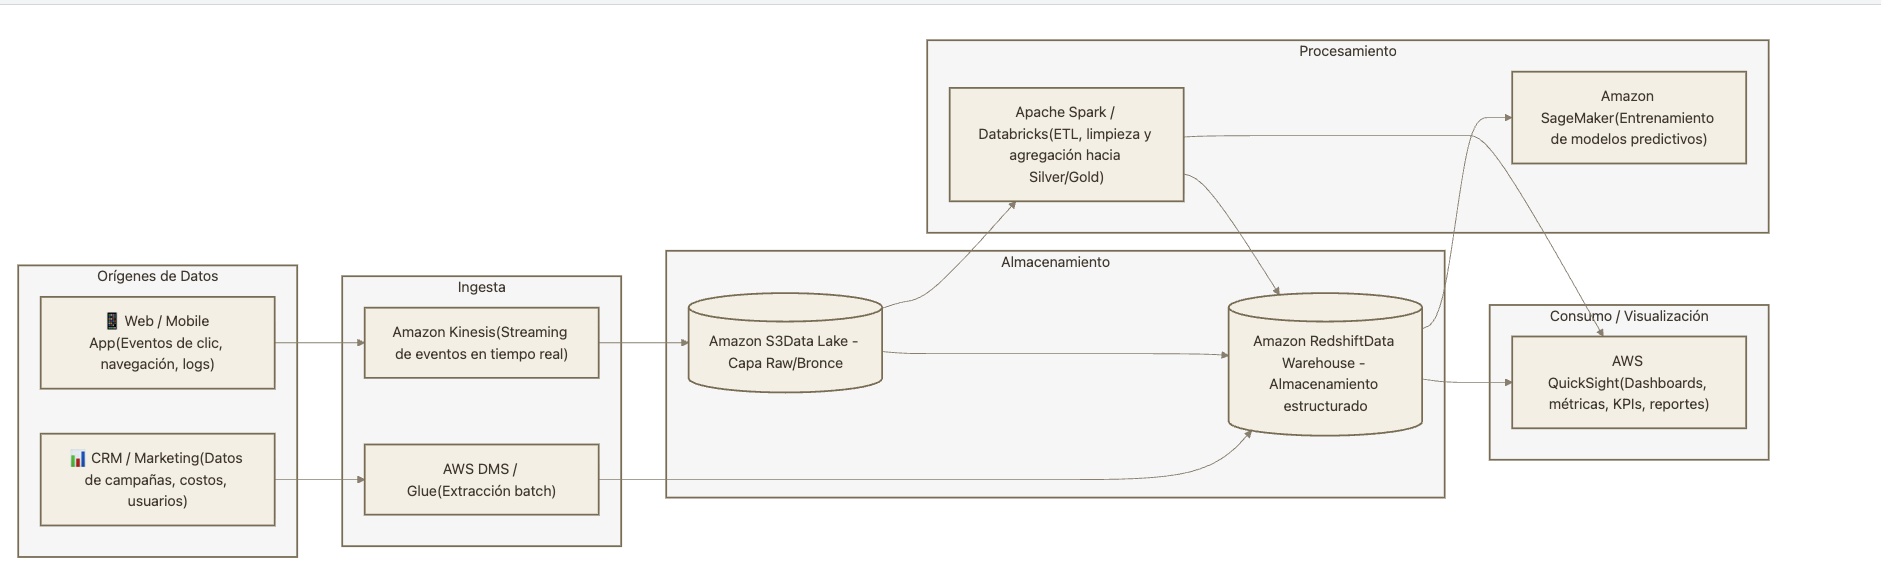

# Descripción de las fases:

## Recopilación (Ingesta): 
Las interacciones del usuario en el sitio web (clics, tiempo en página, dispositivo) se capturan mediante un pixel o SDK y se envían como eventos JSON a un servicio de streaming de alta concurrencia como Amazon Kinesis o Google Cloud Pub/Sub.

## Almacenamiento: 
Los datos crudos aterrizan inicialmente en un Data Lake altamente escalable y económico, como Amazon S3. Una vez procesados, los datos estructurados y listos para negocio se almacenan en un Data Warehouse como Amazon Redshift o Google BigQuery.

## Procesamiento: 
Los datos crudos necesitan ser transformados, limpiados y cruzados (ej. unir eventos web con perfiles de usuarios). Aquí se despliegan motores de procesamiento distribuido como Apache Spark (gestionado a través de Databricks o AWS Glue) para ejecutar estas canalizaciones ETL (Extracción, Transformación y Carga) de manera eficiente.

## Análisis y Predicción: 
Científicos y analistas de datos consumen la información estructurada desde el Data Warehouse para entrenar modelos de Machine Learning (como el Random Forest para predecir conversiones) utilizando entornos como Amazon SageMaker.

## Visualización: 
Herramientas de inteligencia de negocios como AWS QuickSight o Looker Studio (Google Data) se conectan directamente al Data Warehouse para actualizar los tableros gerenciales en tiempo real, monitoreando el ROI, la tasa de conversión y los resultados de las pruebas A/B.

# 8. Integración del proceso de optimización
El ciclo de optimización digital no es lineal, sino un bucle de retroalimentación continua donde cada fase detona la siguiente. Los componentes se complementan de la siguiente manera:

## Datos: 

Es la materia prima pura (logs, tiempos de sesión, categorías de dispositivos). Sin datos centralizados y confiables, las decisiones dependen de la intuición.

## Análisis: 
Es el proceso de interrogar los datos. A través de la exploración estadística, se transforman los registros individuales en tendencias agregadas (ej. descubrir que el 70% del tráfico es móvil pero su tasa de conversión está estancada).

## Hallazgo: 
Es el insight o revelación de negocio que surge del análisis. Constituye el problema específico o la oportunidad detectada (ej. existe una alta fricción en el formulario de registro para pantallas pequeñas).

## Hipótesis: 
Es la solución propuesta basada en el hallazgo. Establece una relación causal que debe comprobarse (ej. si simplificamos el registro con Social Login, entonces aumentarán las conversiones móviles).

## Experimentación: 
Es el mecanismo científico (Prueba A/B) para validar la hipótesis en el mundo real. Permite mitigar riesgos probando el cambio solo en una fracción del tráfico.

## Evaluación: 
Es la medición del impacto del experimento utilizando rigor estadístico y métricas de negocio (ROI, CLV, Tasa de Conversión). Determina si la hipótesis fue correcta o si debe descartarse.

## Predicción: 
Una vez que entendemos qué funciona, aplicamos modelos de Machine Learning para anticipar el comportamiento futuro. Si sabemos qué variables llevan a una conversión, podemos predecir qué nuevos usuarios tienen alta intención de compra.

## Optimización:
Es la consolidación de todo el proceso. Se despliega la versión ganadora del experimento al 100% de los usuarios, se enfocan los presupuestos de marketing en los perfiles predecidos como "altamente rentables", y el nuevo estándar del sitio web comienza a generar Datos frescos, reiniciando el ciclo para buscar el siguiente margen de mejora.


# 9.    A partir de los resultados y análisis realizados, presenta recomendaciones para la estrategia digital. Las recomendaciones deberán estar sustentadas en los datos, hallazgos y métricas analizadas.



# A partir de los hallazgos del análisis exploratorio, la conceptualización del modelo predictivo y la estrategia de experimentación, las siguientes son las recomendaciones clave para optimizar la estrategia digital del negocio:

## 1. Transición inmediata a un enfoque de diseño y desarrollo "Mobile-First"

## Sustento en datos: 
El análisis reveló que el segmento móvil genera 30,911 conversiones, superando ampliamente las 12,963 de escritorio, pero manteniendo una tasa promedio de conversión casi idéntica.

## Impacto esperado: 
Al implementar flujos de compra a un clic y Social Login para reducir la fricción en pantallas pequeñas, se capitalizará el canal con mayor volumen de tráfico, logrando un aumento directo en el volumen total de conversiones y una mejora en el ROI.

## 2. Sincronización de presupuestos publicitarios con la temporalidad de conversión

## Sustento en datos: 
Los resultados exploratorios mostraron que los jueves y viernes presentan picos significativos en el volumen de conversiones.

## Impacto esperado: 
Se recomienda concentrar la mayor parte del presupuesto de campañas de Paid Search y Social Media (pauta publicitaria) entre los miércoles por la tarde y los viernes. Esto reducirá el Costo de Adquisición de Clientes (CAC) al invertir los recursos exactamente en los momentos de mayor intención de compra comprobada.

## 3. Implementación de un modelo de atribución Basado en la Posición (Data-Driven)

## Sustento en datos: 
Los usuarios interactúan con múltiples fuentes (Organic, Social, Direct) y páginas (blog, home, products) antes de convertir. Un modelo de último clic oculta el valor de los esfuerzos de atracción inicial.

## Impacto esperado: 
Al distribuir el crédito de la conversión (ej. 40% al primer clic, 20% al medio, 40% al cierre), el equipo de marketing digital podrá justificar el presupuesto en canales de "descubrimiento" como redes sociales, asegurando que el embudo de ventas nunca se quede sin tráfico nuevo.

## 4. Despliegue de analítica predictiva para campañas de retargeting dinámico

Sustento en datos: Se cuenta con variables sólidas (Avg Session Duration, Page Views, Source) que un modelo de clasificación (ej. Random Forest) puede procesar para calcular la probabilidad de conversión de un usuario en tiempo real.

## Impacto esperado: 
En lugar de lanzar descuentos generales, la plataforma podrá identificar automáticamente a los usuarios de "alta probabilidad que están a punto de abandonar" e impactarlos con incentivos personalizados (ej. envío gratis durante esa sesión), maximizando las conversiones sin erosionar los márgenes de ganancia.

# Evidencia 3: Diseño del Experimento (Prueba A/B)
## [Nota: El siguiente componente se presenta como una propuesta conceptual para futura implementación en el entorno digital]

## 1. Título del Experimento:
Optimización del flujo de Conversión (Sign Up / Purchase) para entorno Mobile-First.

## 2. Justificación (Basada en Datos):
El análisis exploratorio indica que el tráfico móvil (Device Category = Mobile) genera el mayor volumen de conversiones totales (30,911), pero su tasa de conversión promedio por sesión es estadísticamente idéntica a la de Desktop. Esto representa una oportunidad para eliminar fricciones específicas de pantallas pequeñas y maximizar el retorno de este segmento mayoritario.

## 3. Hipótesis de la Prueba:
Si simplificamos el proceso de registro y compra en dispositivos móviles eliminando campos manuales e introduciendo autenticación rápida, entonces la tasa de conversión promedio móvil aumentará de manera significativa, porque se reduce la carga cognitiva y la fricción de teclear en pantallas pequeñas.

## 4. Definición de Variantes:

## Versión de Control (A): 
El flujo de registro y pago actual. Es responsivo, pero requiere llenar manualmente un formulario estándar de múltiples campos (Nombre, Apellidos, Email, Contraseña, etc.).

## Versión Alternativa (B): 
Nuevo flujo "Mobile-First". Incluye:

Registro e inicio de sesión a un clic (Social Login mediante Google/Apple).

Botones de acción (Call-to-Action) flotantes y siempre visibles ("Comprar ahora").

Activación automática de teclado numérico para campos de tarjeta o teléfono.

## 5. Segmentación de la Audiencia:

## Filtro: 
Usuarios con Device Category == 'Mobile'.

## Distribución de Tráfico: 
50% del tráfico móvil será dirigido a la Versión A (Control) y el 50% a la Versión B (Alternativa) de forma aleatoria.

## 6. Métricas de Evaluación (KPIs):

## Métrica Principal: 
Promedio de conversiones (Conversions mean) y Tasa de Conversión (Conversion Rate) por sesión.

## Métrica Secundaria: 
Tasa de abandono (Bounce Rate) en la página del carrito/registro.

## 7. Criterio de Éxito:
El experimento será exitoso si la Versión B demuestra un incremento en la métrica principal con un nivel de significancia estadística del 95% (p-value < 0.05) sin afectar negativamente la métrica secundaria, tras un periodo de prueba mínimo de 2 a 3 semanas.


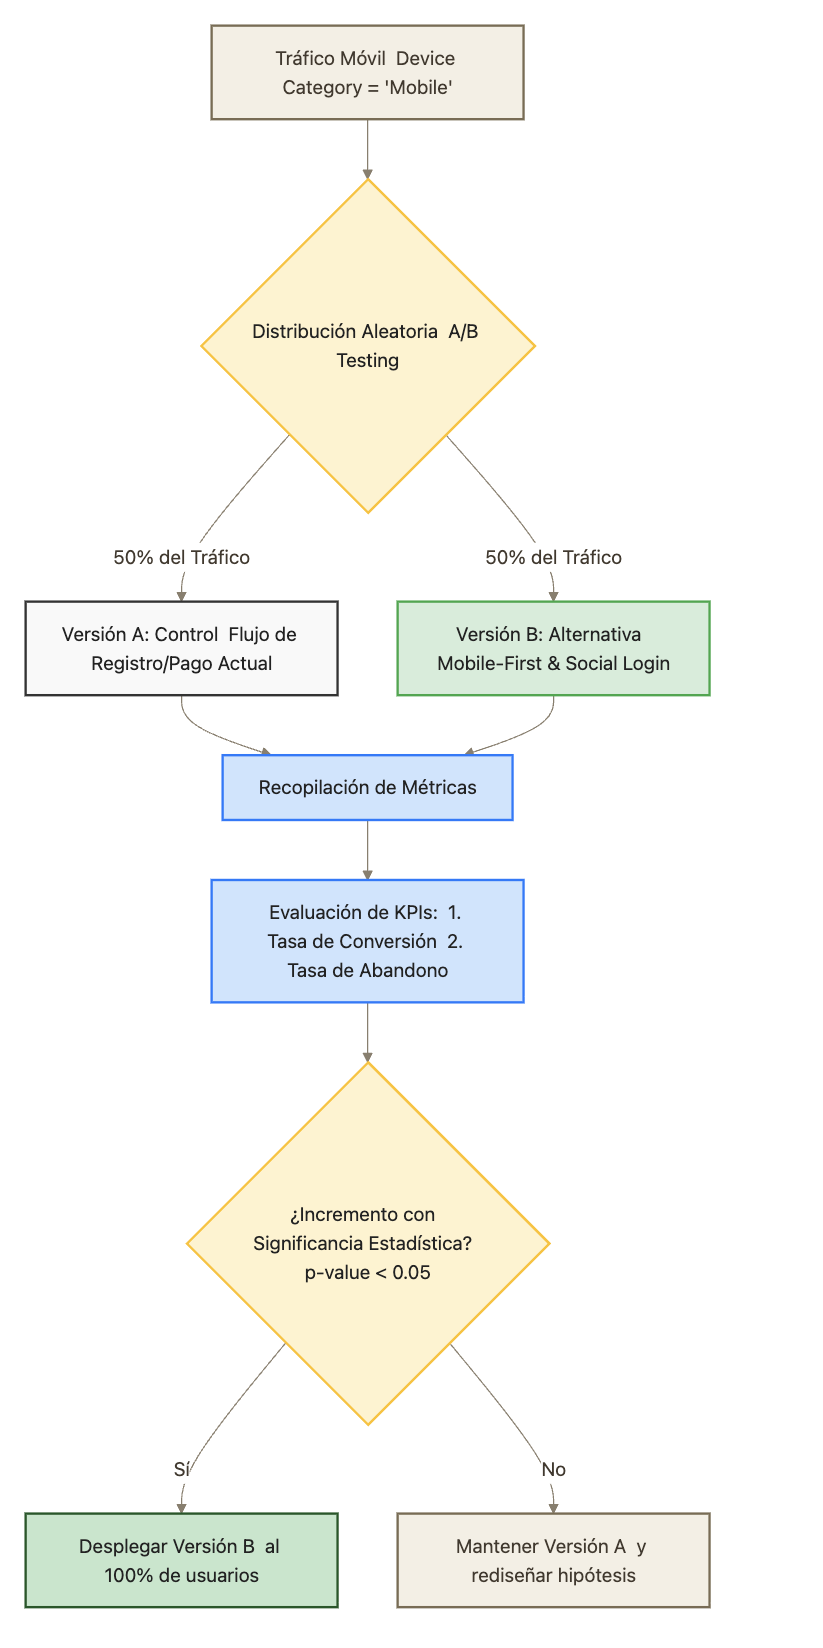